In [1]:
# If you haven't installed required packages, uncomment and run:
# !pip install tensorflow scikit-learn matplotlib seaborn pandas

import os
import random
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import time

# Enable mixed precision for speed on 1GB GPU
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')
print("Mixed precision enabled:", mixed_precision.global_policy())

C:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


Mixed precision enabled: <DTypePolicy "mixed_float16">


In [23]:
class Config:
    # ----- UPDATE THESE PATHS -----
    TRAIN_DIR = r"D:\Wheat Dataset\Dataset\split_dataset\train"
    VAL_DIR   = r"D:\Wheat Dataset\Dataset\split_dataset\val"
    TEST_DIR  = r"D:\Wheat Dataset\Dataset\split_dataset\test"
    
    # Classes (must match folder names)
    CLASS_NAMES = ['Black Point', 'Healthy', 'Leaf Blight', 'leaf rust', 
                   'Mildew', 'Septoria', 'stem rust', 'Wheat Blast', 'Yellow Rust']
    NUM_CLASSES = len(CLASS_NAMES)
    
    # Image parameters
    IMG_SIZE = 224
    BATCH_SIZE = 8          # Reduce to 8 if you run out of memory first training stage is trained by 16 batch size and seconds by 8
    
    # Training hyperparameters
    INITIAL_LR = 1e-3
    FINE_TUNE_LR = 1e-5
    EPOCHS_STAGE1 = 15
    EPOCHS_STAGE2 = 20
    
    # Reproducibility
    SEED = 42

config = Config()

# Set seeds
random.seed(config.SEED)
np.random.seed(config.SEED)
tf.random.set_seed(config.SEED)

print("Configuration loaded.")
print("Classes:", config.CLASS_NAMES)

Configuration loaded.
Classes: ['Black Point', 'Healthy', 'Leaf Blight', 'leaf rust', 'Mildew', 'Septoria', 'stem rust', 'Wheat Blast', 'Yellow Rust']


In [26]:
AUTOTUNE = tf.data.AUTOTUNE

def create_datasets():
    """Load datasets, apply preprocessing & augmentation."""
    train_ds = tf.keras.preprocessing.image_dataset_from_directory(
        config.TRAIN_DIR,
        image_size=(config.IMG_SIZE, config.IMG_SIZE),
        batch_size=config.BATCH_SIZE,
        label_mode='int',
        shuffle=True,
        seed=config.SEED
    )
    
    val_ds = tf.keras.preprocessing.image_dataset_from_directory(
        config.VAL_DIR,
        image_size=(config.IMG_SIZE, config.IMG_SIZE),
        batch_size=config.BATCH_SIZE,
        label_mode='int',
        shuffle=False,
        seed=config.SEED
    )
    
    test_ds = tf.keras.preprocessing.image_dataset_from_directory(
        config.TEST_DIR,
        image_size=(config.IMG_SIZE, config.IMG_SIZE),
        batch_size=config.BATCH_SIZE,
        label_mode='int',
        shuffle=False,
        seed=config.SEED
    )
    
    class_names = train_ds.class_names
    print("Classes found:", class_names)
    print("Training batches:", len(train_ds))
    print("Validation batches:", len(val_ds))
    print("Test batches:", len(test_ds))
    
    # Preprocessing function (EfficientNet specific)
    def preprocess(image, label):
        image = tf.cast(image, tf.float32)
        image = preprocess_input(image)
        return image, label
    
    # Augmentation (only for training)
    def augment(image, label):
        image = tf.image.random_flip_left_right(image)
        image = tf.image.random_brightness(image, 0.1)
        image = tf.image.random_contrast(image, 0.9, 1.1)
        return image, label
    
    # Apply preprocessing to all datasets
    train_ds = train_ds.map(preprocess, num_parallel_calls=AUTOTUNE)
    val_ds   = val_ds.map(preprocess, num_parallel_calls=AUTOTUNE)
    test_ds  = test_ds.map(preprocess, num_parallel_calls=AUTOTUNE)
    
    # Apply augmentation only to training set
    train_ds = train_ds.map(augment, num_parallel_calls=AUTOTUNE)
    
    # Cache and prefetch for performance
    train_ds = train_ds.cache().prefetch(AUTOTUNE)
    val_ds   = val_ds.cache().prefetch(AUTOTUNE)
    test_ds  = test_ds.cache().prefetch(AUTOTUNE)
    
    return train_ds, val_ds, test_ds, class_names

In [11]:
def build_model(backbone_trainable=False):
    """Builds EfficientNet-B0 classifier."""
    inputs = layers.Input(shape=(config.IMG_SIZE, config.IMG_SIZE, 3))
    
    # Load pretrained backbone without top
    backbone = EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(config.IMG_SIZE, config.IMG_SIZE, 3)
    )
    backbone.trainable = backbone_trainable
    
    x = backbone(inputs)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    
    # Final layer with float32 for stability
    outputs = layers.Dense(config.NUM_CLASSES, activation='softmax', dtype='float32')(x)
    
    model = models.Model(inputs, outputs, name='EfficientNetB0')
    return model

In [13]:
def get_callbacks(stage_name):
    """Returns training callbacks."""
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', patience=8, restore_best_weights=True, mode='max'
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.3, patience=4, min_lr=1e-7, verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            f'best_model_{stage_name}.keras',
            monitor='val_accuracy', save_best_only=True, verbose=1
        ),
        tf.keras.callbacks.CSVLogger(f'training_log_{stage_name}.csv')
    ]

In [14]:
def compute_class_weights(train_ds):
    """Compute class weights from training labels."""
    all_labels = np.concatenate([y for _, y in train_ds], axis=0)
    class_weights = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(all_labels),
        y=all_labels
    )
    weight_dict = {i: class_weights[i] for i in range(len(class_weights))}
    print("Class weights:", {config.CLASS_NAMES[i]: f"{w:.3f}" for i, w in weight_dict.items()})
    return weight_dict

In [15]:
# 1. Load datasets
train_ds, val_ds, test_ds, class_names = create_datasets()

# 2. Compute class weights (to handle imbalance)
class_weights = compute_class_weights(train_ds)

Found 8409 files belonging to 9 classes.
Found 1050 files belonging to 9 classes.
Found 1058 files belonging to 9 classes.
Classes found: ['Black Point', 'Healthy', 'Leaf Blight', 'Mildew', 'Septoria', 'Wheat Blast', 'Yellow Rust', 'leaf rust', 'stem rust']
Training batches: 1052
Validation batches: 132
Test batches: 133
Class weights: {'Black Point': '1.460', 'Healthy': '0.923', 'Leaf Blight': '0.634', 'leaf rust': '1.081', 'Mildew': '1.021', 'Septoria': '1.168', 'stem rust': '0.865', 'Wheat Blast': '0.716', 'Yellow Rust': '2.920'}


In [16]:
# 3. Build model with frozen EfficientNetB0 backbone
model = build_model(backbone_trainable=False)
model.summary()

Model: "EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 256, 256, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb0 (Functional)          │ (None, 8, 8, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 1280)                │           5,120 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         655,872 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 9)                   │           2,313 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,844,204 (18.48 MB)

 Trainable params: 792,073 (3.02 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [9]:
# ----- STAGE 1: Train head only -----
print("\n" + "="*50)
print("STAGE 1: Training classification head")
print("="*50)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=config.INITIAL_LR),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=config.EPOCHS_STAGE1,
    callbacks=get_callbacks('stage1'),
    class_weight=class_weights,
    verbose=1
)


STAGE 1: Training classification head
Epoch 1/15
526/526 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.6641 - loss: 0.9922
Epoch 1: val_accuracy improved from None to 0.86381, saving model to best_model_stage1.keras

Epoch 1: finished saving model to best_model_stage1.keras
526/526 ━━━━━━━━━━━━━━━━━━━━ 4124s 8s/step - accuracy: 0.7562 - loss: 0.7231 - val_accuracy: 0.8638 - val_loss: 0.3659 - learning_rate: 0.0010
Epoch 2/15
526/526 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8526 - loss: 0.4203
Epoch 2: val_accuracy improved from 0.86381 to 0.89333, saving model to best_model_stage1.keras

Epoch 2: finished saving model to best_model_stage1.keras
526/526 ━━━━━━━━━━━━━━━━━━━━ 3605s 7s/step - accuracy: 0.8601 - loss: 0.3968 - val_accuracy: 0.8933 - val_loss: 0.3052 - learning_rate: 0.0010
Epoch 3/15
526/526 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8869 - loss: 0.2847
Epoch 3: val_accuracy improved from 0.89333 to 0.90667, saving model to best_model_stage1.keras

Epoch 3: finishe

In [7]:
best_stage1_model = tf.keras.models.load_model('best_model_stage1.keras')

In [22]:
print("IMG_SIZE =", config.IMG_SIZE)
print("BATCH_SIZE =", config.BATCH_SIZE)

IMG_SIZE = 256
BATCH_SIZE = 8


In [27]:
# ==================================================
# STAGE 2: FINE-TUNING (Corrected & Optimized for 1GB GPU)
# ==================================================

import tensorflow as tf
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# ------------------------------
# 1. Set correct parameters
# ------------------------------
config.IMG_SIZE = 224          # Model was trained with 224
config.BATCH_SIZE = 8           # Reduce from 16 to fit memory
print(f"Image size: {config.IMG_SIZE}, Batch size: {config.BATCH_SIZE}")

# ------------------------------
# 2. Reload datasets with new batch size & size
# ------------------------------
AUTOTUNE = tf.data.AUTOTUNE

def create_datasets():
    train_ds = tf.keras.preprocessing.image_dataset_from_directory(
        config.TRAIN_DIR,
        image_size=(config.IMG_SIZE, config.IMG_SIZE),
        batch_size=config.BATCH_SIZE,
        label_mode='int',
        shuffle=True,
        seed=config.SEED
    )
    val_ds = tf.keras.preprocessing.image_dataset_from_directory(
        config.VAL_DIR,
        image_size=(config.IMG_SIZE, config.IMG_SIZE),
        batch_size=config.BATCH_SIZE,
        label_mode='int',
        shuffle=False,
        seed=config.SEED
    )
    test_ds = tf.keras.preprocessing.image_dataset_from_directory(
        config.TEST_DIR,
        image_size=(config.IMG_SIZE, config.IMG_SIZE),
        batch_size=config.BATCH_SIZE,
        label_mode='int',
        shuffle=False,
        seed=config.SEED
    )
    class_names = train_ds.class_names

    def preprocess(image, label):
        image = tf.cast(image, tf.float32)
        image = tf.keras.applications.efficientnet.preprocess_input(image)
        return image, label

    def augment(image, label):
        image = tf.image.random_flip_left_right(image)
        image = tf.image.random_brightness(image, 0.1)
        image = tf.image.random_contrast(image, 0.9, 1.1)
        return image, label

    train_ds = train_ds.map(preprocess, num_parallel_calls=AUTOTUNE)
    val_ds   = val_ds.map(preprocess, num_parallel_calls=AUTOTUNE)
    test_ds  = test_ds.map(preprocess, num_parallel_calls=AUTOTUNE)

    train_ds = train_ds.map(augment, num_parallel_calls=AUTOTUNE)

    train_ds = train_ds.cache().prefetch(AUTOTUNE)
    val_ds   = val_ds.cache().prefetch(AUTOTUNE)
    test_ds  = test_ds.cache().prefetch(AUTOTUNE)

    return train_ds, val_ds, test_ds, class_names

train_ds, val_ds, test_ds, class_names = create_datasets()
print("Datasets reloaded.")

# ------------------------------
# 3. Compute class weights (if needed)
# ------------------------------
all_labels = np.concatenate([y for _, y in train_ds], axis=0)
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(all_labels),
    y=all_labels
)
class_weights = {i: class_weights[i] for i in range(len(class_weights))}
print("Class weights:", class_weights)

# ------------------------------
# 4. Load the best model from Stage 1
# ------------------------------
model = tf.keras.models.load_model('best_model_stage1.keras')
print("Best Stage 1 model loaded.")

# Quick sanity check – should show accuracy ~0.94
for x, y in val_ds.take(1):
    loss, acc = model.evaluate(x, y, verbose=0)
    print(f"Sanity check – validation accuracy on one batch: {acc:.4f}")

# ------------------------------
# 5. Unfreeze only a small part of the backbone
# ------------------------------
backbone = model.get_layer('efficientnetb0')
backbone.trainable = True

# Freeze first 90% of layers – only last 10% will be fine‑tuned
freeze_until = int(0.9 * len(backbone.layers))
for layer in backbone.layers[:freeze_until]:
    layer.trainable = False
print(f"Unfroze {len(backbone.layers) - freeze_until} out of {len(backbone.layers)} layers.")

# ------------------------------
# 6. Recompile with very low learning rate
# ------------------------------
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# ------------------------------
# 7. Callbacks for Stage 2
# ------------------------------
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy', patience=8, restore_best_weights=True, mode='max'
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.3, patience=4, min_lr=1e-7, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        'best_model_stage2.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.CSVLogger('training_log_stage2.csv')
]

# -

Image size: 224, Batch size: 8
Found 8409 files belonging to 9 classes.
Found 1050 files belonging to 9 classes.
Found 1058 files belonging to 9 classes.
Datasets reloaded.
Class weights: {0: np.float64(1.4598958333333334), 1: np.float64(0.9232542819499341), 2: np.float64(0.634306404163838), 3: np.float64(1.0814043209876543), 4: np.float64(1.0211293260473588), 5: np.float64(1.1679166666666667), 6: np.float64(0.8651234567901235), 7: np.float64(0.7159642401021712), 8: np.float64(2.919791666666667)}
Best Stage 1 model loaded.
Sanity check – validation accuracy on one batch: 1.0000
Unfroze 24 out of 238 layers.


In [30]:
#-----------------------------
# 8. Fine-tune (8 epochs – you can adjust)
# ------------------------------
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,                     # you can change to 10 or 15
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=1
)


Epoch 1/8
1052/1052 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - accuracy: 0.8659 - loss: 0.4588
Epoch 1: val_accuracy improved from 0.91048 to 0.92190, saving model to best_model_stage2.keras

Epoch 1: finished saving model to best_model_stage2.keras
1052/1052 ━━━━━━━━━━━━━━━━━━━━ 10642s 10s/step - accuracy: 0.8692 - loss: 0.4255 - val_accuracy: 0.9219 - val_loss: 0.2591 - learning_rate: 1.0000e-05
Epoch 2/8
1052/1052 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.8794 - loss: 0.3656
Epoch 2: val_accuracy improved from 0.92190 to 0.92667, saving model to best_model_stage2.keras

Epoch 2: finished saving model to best_model_stage2.keras
1052/1052 ━━━━━━━━━━━━━━━━━━━━ 10324s 10s/step - accuracy: 0.8767 - loss: 0.3840 - val_accuracy: 0.9267 - val_loss: 0.2388 - learning_rate: 1.0000e-05
Epoch 3/8
1052/1052 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.8838 - loss: 0.3404
Epoch 3: val_accuracy did not improve from 0.92667
1052/1052 ━━━━━━━━━━━━━━━━━━━━ 9011s 9s/step - accuracy: 0.8814 - loss: 0.3395

In [31]:
# Load the best model from Stage 2 (saved at epoch with highest validation accuracy)
best_stage2 = tf.keras.models.load_model('best_model_stage2.keras')
print("Best Stage 2 model loaded.")

# Evaluate on test set
test_loss_stage2, test_acc_stage2 = best_stage2.evaluate(test_ds, verbose=1)
print(f"\n✅ Stage 2 Test Accuracy: {test_acc_stage2:.4f}")

Best Stage 2 model loaded.
133/133 ━━━━━━━━━━━━━━━━━━━━ 493s 4s/step - accuracy: 0.9423 - loss: 0.1752

✅ Stage 2 Test Accuracy: 0.9423


In [32]:
# Load the best model from Stage 1
best_stage1 = tf.keras.models.load_model('best_model_stage1.keras')
print("Best Stage 1 model loaded.")

# Evaluate on test set
test_loss_stage1, test_acc_stage1 = best_stage1.evaluate(test_ds, verbose=0)
print(f"Stage 1 Test Accuracy: {test_acc_stage1:.4f}")

Best Stage 1 model loaded.
Stage 1 Test Accuracy: 0.9527


133/133 ━━━━━━━━━━━━━━━━━━━━ 473s 4s/step

Classification Report (Stage 2):
              precision    recall  f1-score   support

 Black Point       0.99      1.00      0.99        80
     Healthy       0.98      0.96      0.97       128
 Leaf Blight       0.93      0.89      0.91       185
      Mildew       0.90      0.92      0.91       109
    Septoria       0.88      0.97      0.92       115
 Wheat Blast       1.00      1.00      1.00       100
 Yellow Rust       0.98      0.91      0.95       136
   leaf rust       0.93      0.94      0.93       164
   stem rust       0.93      0.95      0.94        41

    accuracy                           0.94      1058
   macro avg       0.95      0.95      0.95      1058
weighted avg       0.94      0.94      0.94      1058



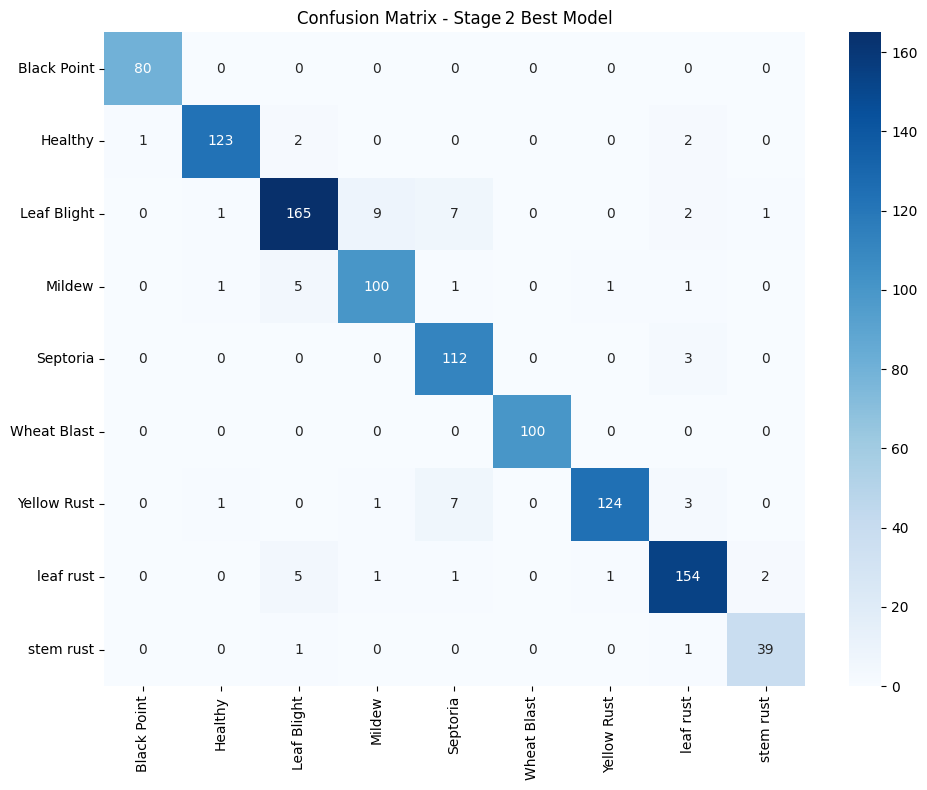

In [33]:
# Get predictions on test set for stage 2
y_true = np.concatenate([y for _, y in test_ds], axis=0)
y_pred = np.argmax(best_stage2.predict(test_ds, verbose=1), axis=1)

# Classification report
print("\nClassification Report (Stage 2):")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion matrix plot
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Stage 2 Best Model')
plt.tight_layout()
plt.savefig('confusion_matrix_stage2.png')
plt.show()

133/133 ━━━━━━━━━━━━━━━━━━━━ 460s 3s/step

Classification Report (Stage 2):
              precision    recall  f1-score   support

 Black Point       0.99      1.00      0.99        80
     Healthy       0.98      0.96      0.97       128
 Leaf Blight       0.93      0.89      0.91       185
      Mildew       0.90      0.92      0.91       109
    Septoria       0.88      0.97      0.92       115
 Wheat Blast       1.00      1.00      1.00       100
 Yellow Rust       0.98      0.91      0.95       136
   leaf rust       0.93      0.94      0.93       164
   stem rust       0.93      0.95      0.94        41

    accuracy                           0.94      1058
   macro avg       0.95      0.95      0.95      1058
weighted avg       0.94      0.94      0.94      1058



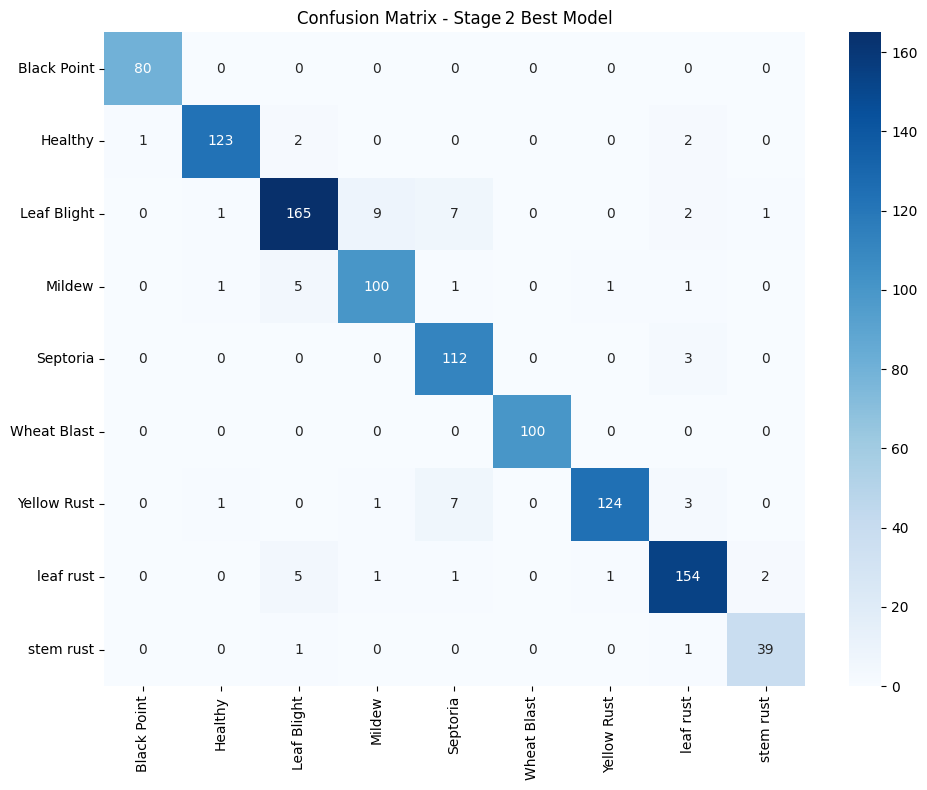

In [34]:
# Get predictions on test set Detailed Classification Report & Confusion Matrix (for Stage 2)
y_true = np.concatenate([y for _, y in test_ds], axis=0)
y_pred = np.argmax(best_stage2.predict(test_ds, verbose=1), axis=1)

# Classification report
print("\nClassification Report (Stage 2):")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion matrix plot
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Stage 2 Best Model')
plt.tight_layout()
plt.savefig('confusion_matrix_stage2.png')
plt.show()

In [ ]:
# Choose the model with higher test accuracy
if test_acc_stage2 >= test_acc_stage1:
    final_model = best_stage2
    print("✅ Stage 2 model selected for deployment.")
else:
    final_model = best_stage1
    print("✅ Stage 1 model selected for deployment.")

# Export to TFLite with optimization
converter = tf.lite.TFLiteConverter.from_keras_model(final_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

with open('wheat_disease_model.tflite', 'wb') as f:
    f.write(tflite_model)

print("TFLite model saved as wheat_disease_model.tflite")

In [35]:
# Load best models from Stage 1 and Stage 2
best_stage1 = tf.keras.models.load_model('best_model_stage1.keras')
best_stage2 = tf.keras.models.load_model('best_model_stage2.keras')
print("Models loaded.")

Models loaded.


In [36]:
# Get true labels from test set
y_true = np.concatenate([y for _, y in test_ds], axis=0)

# Predict for Stage 1
y_pred_stage1 = np.argmax(best_stage1.predict(test_ds, verbose=1), axis=1)

# Predict for Stage 2
y_pred_stage2 = np.argmax(best_stage2.predict(test_ds, verbose=1), axis=1)

print("Predictions ready.")

133/133 ━━━━━━━━━━━━━━━━━━━━ 467s 3s/step
133/133 ━━━━━━━━━━━━━━━━━━━━ 479s 4s/step
Predictions ready.


In [38]:
from sklearn.metrics import precision_recall_fscore_support

In [39]:
from sklearn.metrics import precision_recall_fscore_support, classification_report, confusion_matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
# Compute precision, recall, f1-score for each class
precision1, recall1, f1_1, support1 = precision_recall_fscore_support(y_true, y_pred_stage1)
precision2, recall2, f1_2, support2 = precision_recall_fscore_support(y_true, y_pred_stage2)

# Create DataFrames for easy plotting
metrics_df1 = pd.DataFrame({
    'Class': class_names,
    'Precision': precision1,
    'Recall': recall1,
    'F1-Score': f1_1,
    'Support': support1
})

metrics_df2 = pd.DataFrame({
    'Class': class_names,
    'Precision': precision2,
    'Recall': recall2,
    'F1-Score': f1_2,
    'Support': support2
})

print("Stage 1 metrics:")
print(metrics_df1.round(3))
print("\nStage 2 metrics:")
print(metrics_df2.round(3))

Stage 1 metrics:
         Class  Precision  Recall  F1-Score  Support
0  Black Point      0.988   1.000     0.994       80
1      Healthy      0.992   0.961     0.976      128
2  Leaf Blight      0.954   0.897     0.925      185
3       Mildew      0.896   0.945     0.920      109
4     Septoria      0.894   0.957     0.924      115
5  Wheat Blast      1.000   1.000     1.000      100
6  Yellow Rust      0.992   0.949     0.970      136
7    leaf rust      0.925   0.976     0.950      164
8    stem rust      0.974   0.902     0.937       41

Stage 2 metrics:
         Class  Precision  Recall  F1-Score  Support
0  Black Point      0.988   1.000     0.994       80
1      Healthy      0.976   0.961     0.969      128
2  Leaf Blight      0.927   0.892     0.909      185
3       Mildew      0.901   0.917     0.909      109
4     Septoria      0.875   0.974     0.922      115
5  Wheat Blast      1.000   1.000     1.000      100
6  Yellow Rust      0.984   0.912     0.947      136
7    leaf r

C:\Users\lenovo\AppData\Local\Temp\ipykernel_13160\71259315.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0,0].set_xticklabels(class_names, rotation=45, ha='right')
C:\Users\lenovo\AppData\Local\Temp\ipykernel_13160\71259315.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0,1].set_xticklabels(class_names, rotation=45, ha='right')
C:\Users\lenovo\AppData\Local\Temp\ipykernel_13160\71259315.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0,2].set_xticklabels(class_names, rotation=45, ha='right')
C:\Users\lenovo\AppData\Local\Temp\ipykernel_13160\71259315.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1,0].set_xtickla

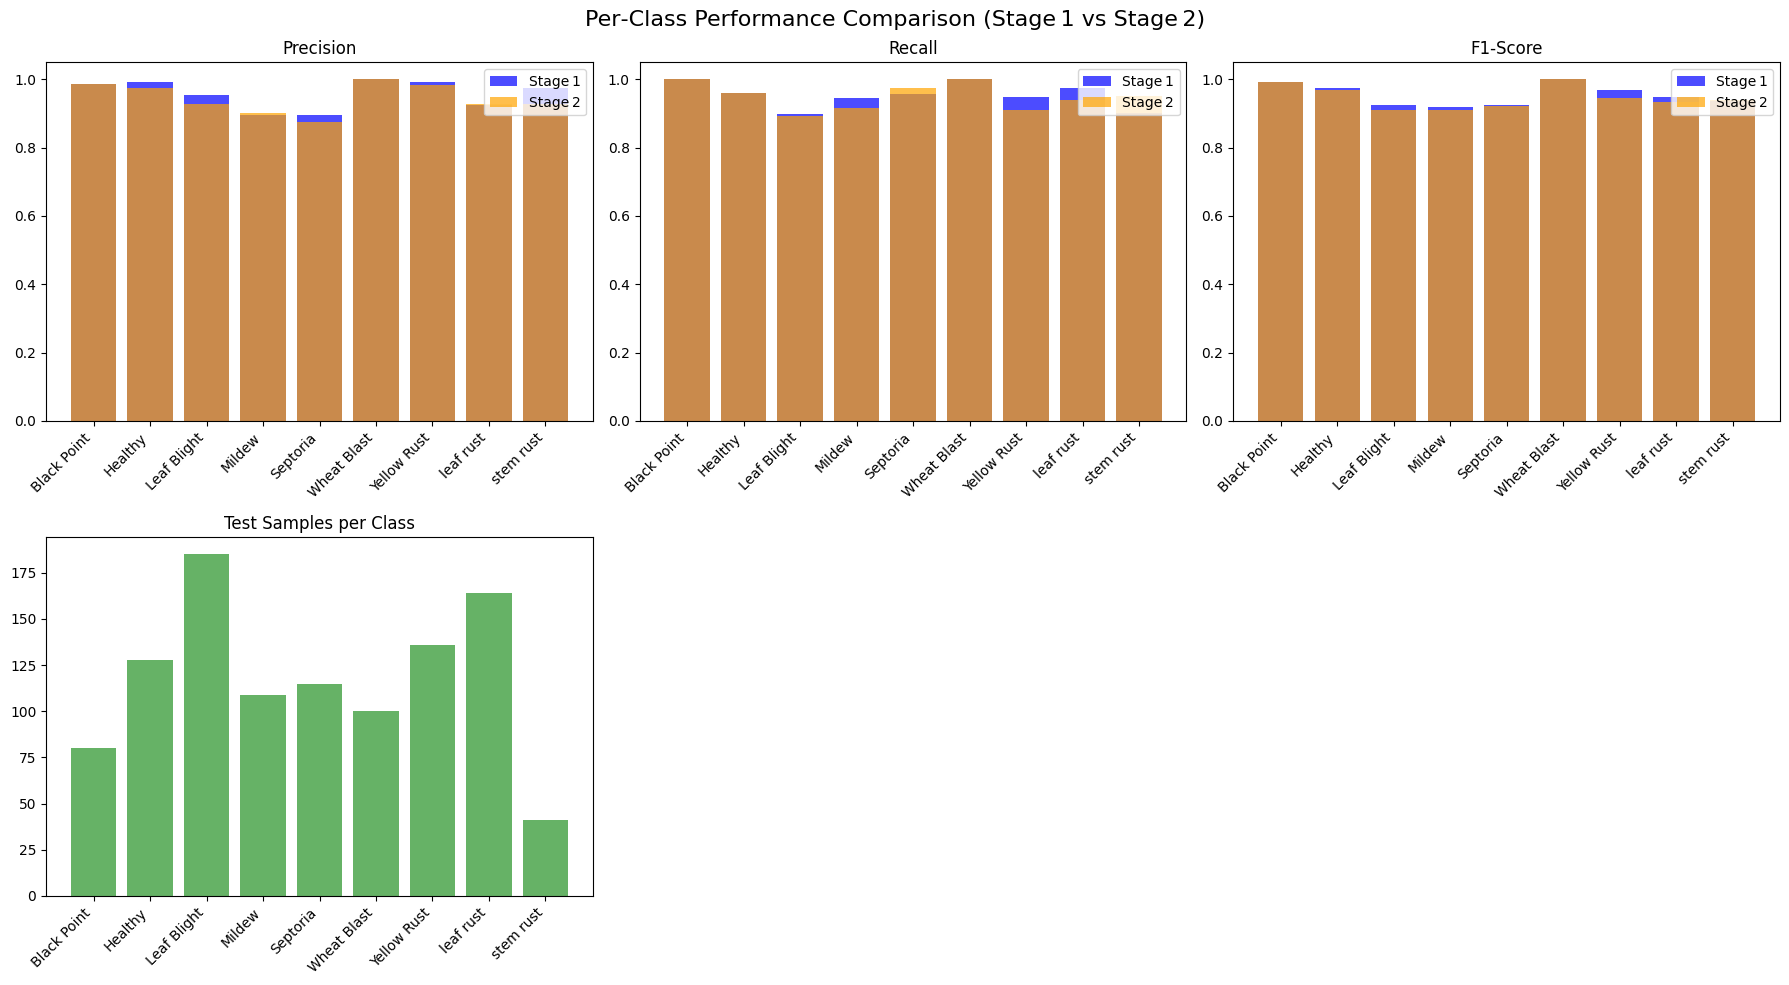

In [41]:
# Set up the matplotlib figure
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Per‑Class Performance Comparison (Stage 1 vs Stage 2)', fontsize=16)

# Precision comparison
axes[0,0].bar(class_names, precision1, alpha=0.7, label='Stage 1', color='blue')
axes[0,0].bar(class_names, precision2, alpha=0.7, label='Stage 2', color='orange')
axes[0,0].set_title('Precision')
axes[0,0].set_xticklabels(class_names, rotation=45, ha='right')
axes[0,0].legend()
axes[0,0].set_ylim(0,1.05)

# Recall comparison
axes[0,1].bar(class_names, recall1, alpha=0.7, label='Stage 1', color='blue')
axes[0,1].bar(class_names, recall2, alpha=0.7, label='Stage 2', color='orange')
axes[0,1].set_title('Recall')
axes[0,1].set_xticklabels(class_names, rotation=45, ha='right')
axes[0,1].legend()
axes[0,1].set_ylim(0,1.05)

# F1-Score comparison
axes[0,2].bar(class_names, f1_1, alpha=0.7, label='Stage 1', color='blue')
axes[0,2].bar(class_names, f1_2, alpha=0.7, label='Stage 2', color='orange')
axes[0,2].set_title('F1‑Score')
axes[0,2].set_xticklabels(class_names, rotation=45, ha='right')
axes[0,2].legend()
axes[0,2].set_ylim(0,1.05)

# Support (number of test samples per class)
axes[1,0].bar(class_names, support1, color='green', alpha=0.6)
axes[1,0].set_title('Test Samples per Class')
axes[1,0].set_xticklabels(class_names, rotation=45, ha='right')

# Hide empty subplots (2,3 grid uses only first 4)
axes[1,1].axis('off')
axes[1,2].axis('off')

plt.tight_layout()
plt.savefig('per_class_metrics_comparison.png')
plt.show()

In [43]:
import tensorflow as tf

# Load your model (choose stage1 or stage2)
model = tf.keras.models.load_model('best_model_stage2.keras')

# Convert with Flex support
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,           # enable built-in ops
    tf.lite.OpsSet.SELECT_TF_OPS               # enable Flex ops
]
# If you want to also use float16 quantization (optional)
converter.target_spec.supported_types = [tf.float16]

tflite_model = converter.convert()

with open('wheat_disease_model_flex.tflite', 'wb') as f:
    f.write(tflite_model)

print("TFLite model with Flex saved.")

INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpvvdvn4f2\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpvvdvn4f2\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmpvvdvn4f2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  2646343942800: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2646343944144: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2646182178128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646182177744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646182176784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646182178896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646182179472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646182177168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646182176400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646182179280: TensorSpec(shape=(), dtype=tf.resource, 

In [46]:
import tensorflow as tf

# Load your model (choose stage1 or stage2)
model = tf.keras.models.load_model('best_model_stage1.keras')

# Convert with Flex support
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,           # enable built-in ops
    tf.lite.OpsSet.SELECT_TF_OPS               # enable Flex ops
]
# If you want to also use float16 quantization (optional)
converter.target_spec.supported_types = [tf.float16]

tflite_model = converter.convert()

with open('wheat_disease_model1_flex1.tflite', 'wb') as f:
    f.write(tflite_model)

print("TFLite model with Flex saved.")

INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpzp2qxi_1\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpzp2qxi_1\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmpzp2qxi_1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  2646171041872: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2646171047248: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2646165032016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646165031632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646165030096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646165032784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646165033360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646165031248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646165030672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2646165033168: TensorSpec(shape=(), dtype=tf.resource, 

Stage 1 log loaded: 15 epochs
Stage 2 log loaded: 8 epochs


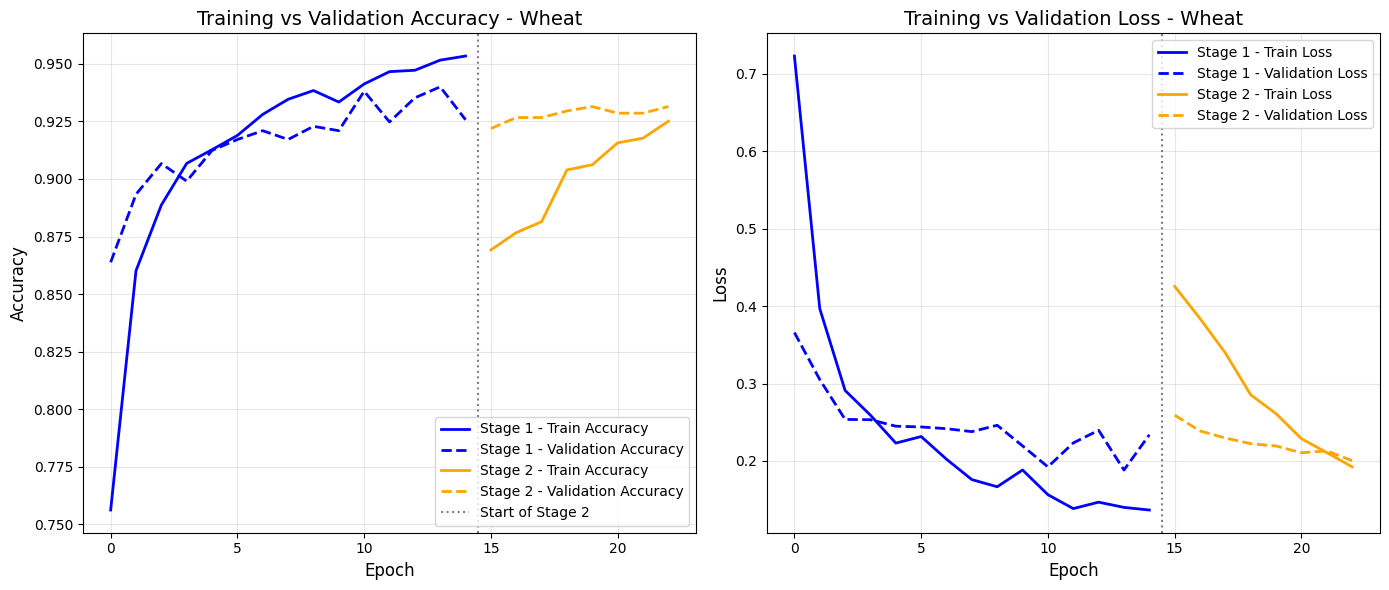

✅ Graph successfully saved as 'wheat_training_curves.png'


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# ==================== LOAD TRAINING LOGS ====================
# Change the paths if your files are in a different folder
stage1_log = pd.read_csv('training_log_stage1.csv')
stage2_log = pd.read_csv('training_log_stage2.csv')

print("Stage 1 log loaded:", len(stage1_log), "epochs")
print("Stage 2 log loaded:", len(stage2_log), "epochs")

# ==================== PLOT TRAINING CURVES ====================
plt.figure(figsize=(14, 6))

# ==================== ACCURACY PLOT ====================
plt.subplot(1, 2, 1)
plt.plot(stage1_log['epoch'], stage1_log['accuracy'], 
         label='Stage 1 - Train Accuracy', color='blue', linewidth=2)
plt.plot(stage1_log['epoch'], stage1_log['val_accuracy'], 
         label='Stage 1 - Validation Accuracy', color='blue', linestyle='--', linewidth=2)

plt.plot(stage2_log['epoch'] + len(stage1_log), stage2_log['accuracy'], 
         label='Stage 2 - Train Accuracy', color='orange', linewidth=2)
plt.plot(stage2_log['epoch'] + len(stage1_log), stage2_log['val_accuracy'], 
         label='Stage 2 - Validation Accuracy', color='orange', linestyle='--', linewidth=2)

plt.axvline(x=len(stage1_log)-0.5, color='gray', linestyle=':', linewidth=1.5, label='Start of Stage 2')
plt.title('Training vs Validation Accuracy - Wheat', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)

# ==================== LOSS PLOT ====================
plt.subplot(1, 2, 2)
plt.plot(stage1_log['epoch'], stage1_log['loss'], 
         label='Stage 1 - Train Loss', color='blue', linewidth=2)
plt.plot(stage1_log['epoch'], stage1_log['val_loss'], 
         label='Stage 1 - Validation Loss', color='blue', linestyle='--', linewidth=2)

plt.plot(stage2_log['epoch'] + len(stage1_log), stage2_log['loss'], 
         label='Stage 2 - Train Loss', color='orange', linewidth=2)
plt.plot(stage2_log['epoch'] + len(stage1_log), stage2_log['val_loss'], 
         label='Stage 2 - Validation Loss', color='orange', linestyle='--', linewidth=2)

plt.axvline(x=len(stage1_log)-0.5, color='gray', linestyle=':', linewidth=1.5)
plt.title('Training vs Validation Loss - Wheat', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('wheat_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Graph successfully saved as 'wheat_training_curves.png'")

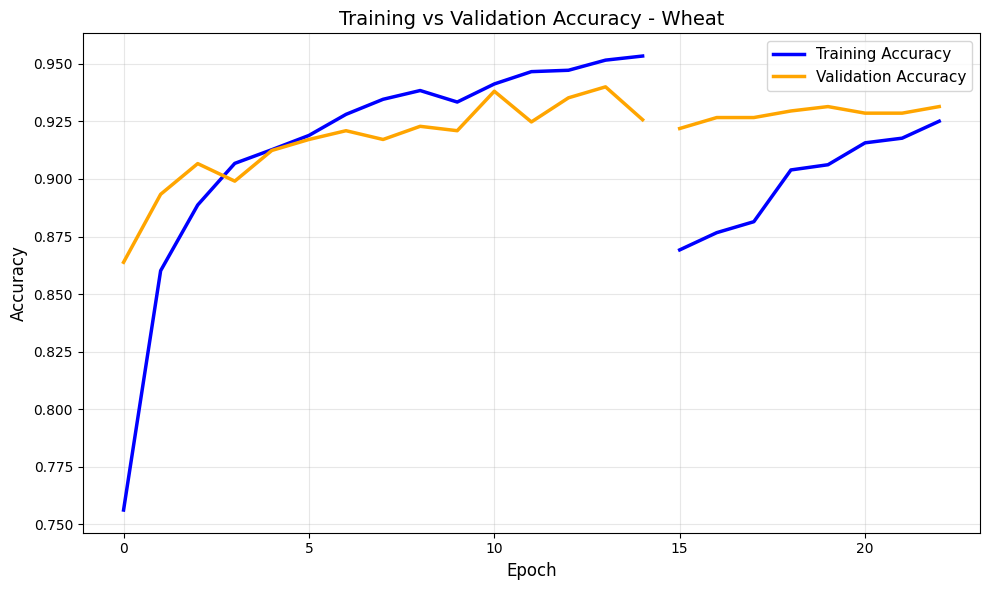

✅ Graph saved as 'wheat_training_vs_validation_accuracy.png'


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the training logs
stage1 = pd.read_csv('training_log_stage1.csv')
stage2 = pd.read_csv('training_log_stage2.csv')

# Combine both stages into one continuous plot
stage1['epoch_global'] = stage1['epoch']
stage2['epoch_global'] = stage2['epoch'] + len(stage1)

# Plot - Simple and clean like your uploaded image
plt.figure(figsize=(10, 6))

plt.plot(stage1['epoch_global'], stage1['accuracy'], 
         label='Training Accuracy', color='blue', linewidth=2.5)
plt.plot(stage1['epoch_global'], stage1['val_accuracy'], 
         label='Validation Accuracy', color='orange', linewidth=2.5)

plt.plot(stage2['epoch_global'], stage2['accuracy'], 
         color='blue', linewidth=2.5)
plt.plot(stage2['epoch_global'], stage2['val_accuracy'], 
         color='orange', linewidth=2.5)

plt.title('Training vs Validation Accuracy - Wheat', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('wheat_training_vs_validation_accuracy.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Graph saved as 'wheat_training_vs_validation_accuracy.png'")

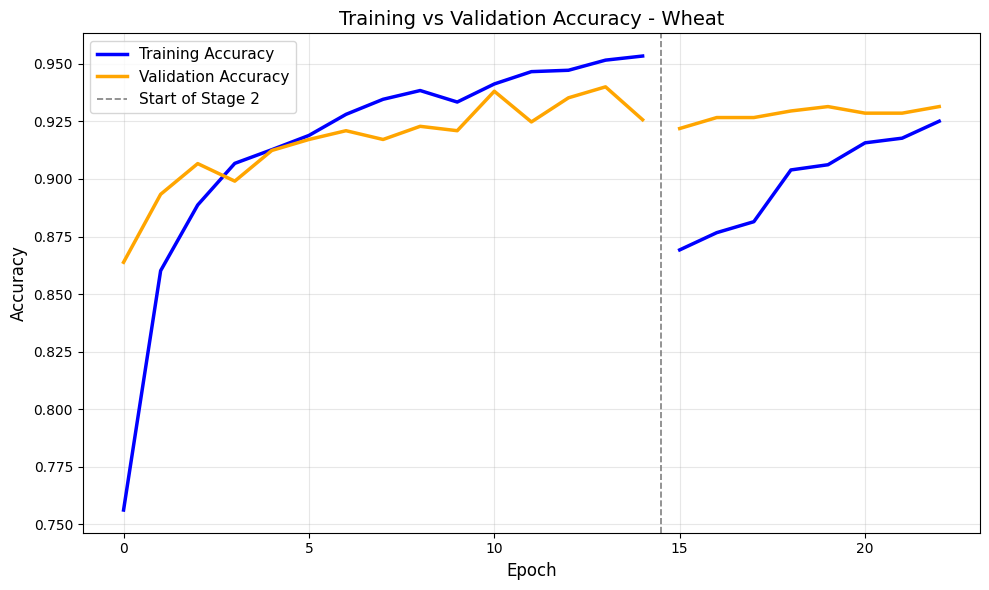

✅ Clean continuous graph saved as 'wheat_training_vs_validation_accuracy_clean.png'


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Load logs
stage1 = pd.read_csv('training_log_stage1.csv')
stage2 = pd.read_csv('training_log_stage2.csv')

# Create continuous epoch numbers
stage1['epoch_global'] = stage1['epoch']
stage2['epoch_global'] = stage2['epoch'] + len(stage1)

# =============== CLEAN CONTINUOUS PLOT ===============
plt.figure(figsize=(10, 6))

# Training Accuracy (continuous blue line)
plt.plot(stage1['epoch_global'], stage1['accuracy'], 
         label='Training Accuracy', color='blue', linewidth=2.5)
plt.plot(stage2['epoch_global'], stage2['accuracy'], 
         color='blue', linewidth=2.5)

# Validation Accuracy (continuous orange line)
plt.plot(stage1['epoch_global'], stage1['val_accuracy'], 
         label='Validation Accuracy', color='orange', linewidth=2.5)
plt.plot(stage2['epoch_global'], stage2['val_accuracy'], 
         color='orange', linewidth=2.5)

# Vertical line showing Stage 1 → Stage 2 transition
plt.axvline(x=len(stage1)-0.5, color='gray', linestyle='--', linewidth=1.2, label='Start of Stage 2')

plt.title('Training vs Validation Accuracy - Wheat', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('wheat_training_vs_validation_accuracy_clean.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Clean continuous graph saved as 'wheat_training_vs_validation_accuracy_clean.png'")

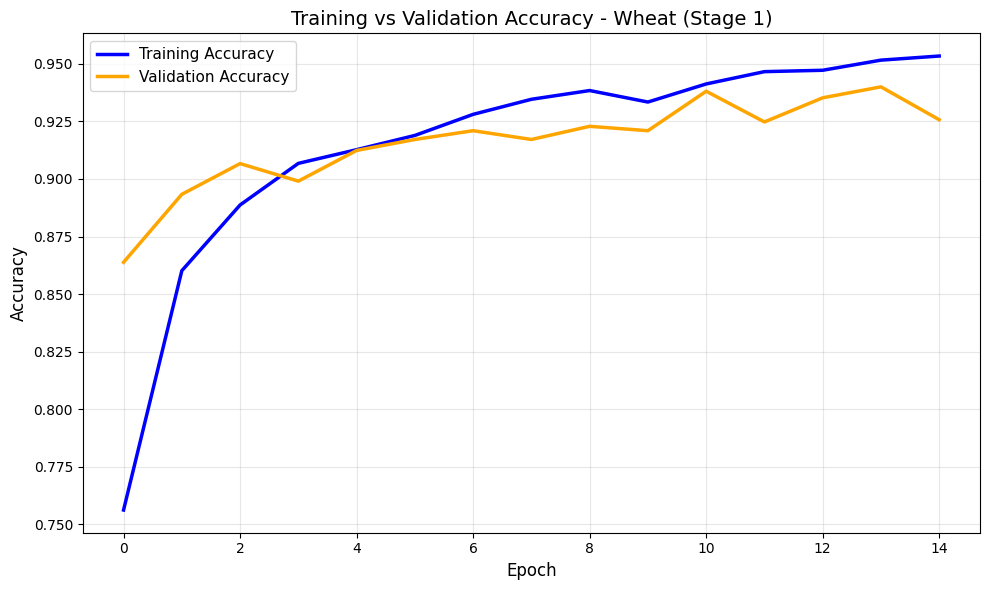

✅ Stage 1 Accuracy graph saved as 'wheat_stage1_accuracy.png'


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Load only Stage 1 log
stage1 = pd.read_csv('training_log_stage1.csv')

# =============== STAGE 1 GRAPH (Clean & Simple) ===============
plt.figure(figsize=(10, 6))

# Training Accuracy
plt.plot(stage1['epoch'], stage1['accuracy'], 
         label='Training Accuracy', color='blue', linewidth=2.5)

# Validation Accuracy
plt.plot(stage1['epoch'], stage1['val_accuracy'], 
         label='Validation Accuracy', color='orange', linewidth=2.5)

plt.title('Training vs Validation Accuracy - Wheat (Stage 1)', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('wheat_stage1_accuracy.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Stage 1 Accuracy graph saved as 'wheat_stage1_accuracy.png'")

In [7]:
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
import numpy as np
import time


keras_model_path = r"D:\Wheat Dataset\best_model_stage2.keras"  


model = tf.keras.models.load_model(keras_model_path)



input_shape  = model.input_shape   # e.g. (None, 224, 224, 3)
output_shape = model.output_shape  # e.g. (None, 9)

print(f"Input shape  : {input_shape}")
print(f"Output shape : {output_shape}")

h = input_shape[1]  # height  e.g. 224
w = input_shape[2]  # width   e.g. 224
c = input_shape[3]  # channels e.g. 3

dummy_input = np.random.rand(1, h, w, c).astype(np.float32)
print(f"Dummy input shape: {dummy_input.shape}")



for _ in range(3):
    model.predict(dummy_input, verbose=0)


times = []

for i in range(50):
    start = time.perf_counter()
    model.predict(dummy_input, verbose=0)
    end   = time.perf_counter()
    times.append((end - start) * 1000)


print("\n========== WHEAT MODEL LATENCY RESULTS ==========")
print(f"Average latency : {np.mean(times):.2f} ms")
print(f"Std deviation   : {np.std(times):.2f} ms")
print(f"Min latency     : {np.min(times):.2f} ms")
print(f"Max latency     : {np.max(times):.2f} ms")
print(f"Median latency  : {np.median(times):.2f} ms")


Input shape  : (None, 224, 224, 3)
Output shape : (None, 9)
Dummy input shape: (1, 224, 224, 3)

========== WHEAT MODEL LATENCY RESULTS ==========
Average latency : 703.32 ms
Std deviation   : 33.43 ms
Min latency     : 630.95 ms
Max latency     : 807.48 ms
Median latency  : 698.35 ms


In [2]:
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf

# Apna wheat keras model load karo
model = tf.keras.models.load_model(
    r"D:\Wheat Dataset\best_model_stage2.keras" 
)

# TFLite mein convert karo
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,
    tf.lite.OpsSet.SELECT_TF_OPS
]

tflite_model = converter.convert()

# Save karo
with open(r"D:\Wheat Dataset\wheat_model_converted.tflite", 'wb') as f:
    f.write(tflite_model)

size_mb = len(tflite_model) / 1024 / 1024
print(f"Saved! Size: {size_mb:.2f} MB")

INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpdrly__oc\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpdrly__oc\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmpdrly__oc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  2163001263120: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2163001262160: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2162958278992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162958278608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162958275728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162958277456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162958276112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162958278032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162958278224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162958278800: TensorSpec(shape=(), dtype=tf.resource, 

In [6]:
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
import numpy as np

# ============================================================
# STEP 1 — Wheat model load karo
# ============================================================
print("Model load ho raha hai...")
model = tf.keras.models.load_model(
    r"D:\Wheat Dataset\best_model_stage2.keras"  # ← apna sahi path likho
)
print("Model load ho gaya!")

# ============================================================
# STEP 2 — Model ki layers check karo (problem dhundho)
# ============================================================
print("\nModel layers:")
for i, layer in enumerate(model.layers):
    print(f"  {i:3d} | {layer.name:<40} | {type(layer).__name__}")

Model load ho raha hai...
Model load ho gaya!

Model layers:
    0 | input_layer                              | InputLayer
    1 | efficientnetb0                           | Functional
    2 | global_average_pooling2d                 | GlobalAveragePooling2D
    3 | batch_normalization                      | BatchNormalization
    4 | dense                                    | Dense
    5 | dropout                                  | Dropout
    6 | dense_1                                  | Dense
    7 | dropout_1                                | Dropout
    8 | dense_2                                  | Dense


In [8]:
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
import numpy as np
import time

# ============================================================
# STEP 1 — Original model load karo
# ============================================================
print("Model load ho raha hai...")
model = tf.keras.models.load_model(
    r"D:\Wheat Dataset\best_model_stage2.keras"  # ← SIRF YEH LINE BADLO
)
print("Load ho gaya!")

# ============================================================
# STEP 2 — BatchNorm fold karke naya model banao
# ============================================================
print("\nBatchNorm fold ho rahi hai...")

inp = model.input
x   = model.layers[1](inp)              # efficientnetb0
x   = model.layers[2](x)               # global_average_pooling2d
x   = model.layers[3](x, training=False) # batch_normalization
x   = model.layers[4](x)               # dense
x   = model.layers[5](x, training=False) # dropout
x   = model.layers[6](x)               # dense_1
x   = model.layers[7](x, training=False) # dropout_1
x   = model.layers[8](x)               # dense_2

new_model = tf.keras.Model(inputs=inp, outputs=x)
print("Naya model ready!")

# ============================================================
# STEP 3 — TFLite mein convert karo
# ============================================================
print("\nConvert ho raha hai...")

converter = tf.lite.TFLiteConverter.from_keras_model(new_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]
converter._experimental_lower_tensor_list_ops = False
converter.experimental_new_converter = True

try:
    tflite_model = converter.convert()
    save_path = r"D:\Wheat Dataset\wheat_fixed.tflite"
    with open(save_path, 'wb') as f:
        f.write(tflite_model)
    print(f"Saved : {save_path}")
    print(f"Size  : {len(tflite_model)/1024/1024:.2f} MB")
    print("\nConversion successful!")

except Exception as e:
    print(f"Error: {e}")

# ============================================================
# STEP 4 — Latency measure karo
# ============================================================
print("\n--- Latency measure ho rahi hai ---")

interpreter = tf.lite.Interpreter(model_path=save_path)
interpreter.allocate_tensors()

input_details  = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print(f"Input shape : {input_details[0]['shape']}")
print(f"Input dtype : {input_details[0]['dtype']}")

input_dtype = input_details[0]['dtype']
dummy_input = np.random.randint(
    0, 256, size=[1, 224, 224, 3], dtype=np.uint8
).astype(input_dtype)

# Warm-up
print("\nWarm-up chal raha hai...")
for _ in range(3):
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()
print("Warm-up complete!")

# Measurement
print("\nLatency measure ho rahi hai (50 runs)...")
times = []
for _ in range(50):
    start = time.perf_counter()
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()
    interpreter.get_tensor(output_details[0]['index'])
    end = time.perf_counter()
    times.append((end - start) * 1000)

print("\n========== WHEAT FIXED TFLITE LATENCY ==========")
print(f"Average latency : {np.mean(times):.2f} ms")
print(f"Std deviation   : {np.std(times):.2f} ms")
print(f"Min latency     : {np.min(times):.2f} ms")
print(f"Max latency     : {np.max(times):.2f} ms")
print(f"Median latency  : {np.median(times):.2f} ms")
print("=================================================")

Model load ho raha hai...
Load ho gaya!

BatchNorm fold ho rahi hai...
Naya model ready!

Convert ho raha hai...
INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpyr5p51_k\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpyr5p51_k\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmpyr5p51_k'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  2163231491088: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2163231492240: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2163133538640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2163133530384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2163133537872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2163133540368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2163133540944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2163133538256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2163133538448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2163133540752: TensorSpec(shape=(), dtype=tf.resource, 

NameError: name 'save_path' is not defined

In [9]:
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
import numpy as np
import time

# ============================================================
# save_path seedha define karo
# ============================================================
save_path = r"D:\Wheat Dataset\wheat_fixed.tflite"  # ← apna sahi path likho

interpreter = tf.lite.Interpreter(model_path=save_path)
interpreter.allocate_tensors()

input_details  = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print(f"Input shape : {input_details[0]['shape']}")
print(f"Input dtype : {input_details[0]['dtype']}")

input_dtype = input_details[0]['dtype']
dummy_input = np.random.randint(
    0, 256, size=[1, 224, 224, 3], dtype=np.uint8
).astype(input_dtype)

# Warm-up
print("\nWarm-up chal raha hai...")
for _ in range(3):
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()
print("Warm-up complete!")

# Measurement
print("\nLatency measure ho rahi hai (50 runs)...")
times = []
for _ in range(50):
    start = time.perf_counter()
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()
    interpreter.get_tensor(output_details[0]['index'])
    end = time.perf_counter()
    times.append((end - start) * 1000)

print("\n========== WHEAT FIXED TFLITE LATENCY ==========")
print(f"Average latency : {np.mean(times):.2f} ms")
print(f"Std deviation   : {np.std(times):.2f} ms")
print(f"Min latency     : {np.min(times):.2f} ms")
print(f"Max latency     : {np.max(times):.2f} ms")
print(f"Median latency  : {np.median(times):.2f} ms")
print("=================================================")

ValueError: Could not open 'D:\Wheat Dataset\wheat_fixed.tflite'.

In [13]:
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
import numpy as np
import time

# ============================================================
# STEP 1 — Model load karo
# ============================================================
print("Model load ho raha hai...")
model = tf.keras.models.load_model(
    r"D:\Wheat Dataset\best_model_stage2.keras"  # ← apna sahi path likho
)
print("Load ho gaya!")

# ============================================================
# STEP 2 — Naya model banao
# ============================================================
inp = model.input
x   = model.layers[1](inp)
x   = model.layers[2](x)
x   = model.layers[3](x, training=False)
x   = model.layers[4](x)
x   = model.layers[5](x, training=False)
x   = model.layers[6](x)
x   = model.layers[7](x, training=False)
x   = model.layers[8](x)
new_model = tf.keras.Model(inputs=inp, outputs=x)
print("Naya model ready!")

# ============================================================
# STEP 3 — Convert karo
# ============================================================
converter = tf.lite.TFLiteConverter.from_keras_model(new_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]
converter._experimental_lower_tensor_list_ops = False
converter.experimental_new_converter = True

print("Converting...")
tflite_model = converter.convert()

# ============================================================
# STEP 4 — SEEDHA C drive mein save karo (permissions issue avoid)
# ============================================================
save_path = r"C:\Users\lenovo\Desktop\wheat_fixed.tflite"
with open(save_path, 'wb') as f:
    f.write(tflite_model)

size_mb = len(tflite_model) / 1024 / 1024
print(f"\nFile saved: {save_path}")
print(f"Size: {size_mb:.2f} MB")

# ============================================================
# STEP 5 — Latency measure karo
# ============================================================
interpreter = tf.lite.Interpreter(model_path=save_path)
interpreter.allocate_tensors()

input_details  = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print(f"\nInput shape : {input_details[0]['shape']}")
print(f"Input dtype : {input_details[0]['dtype']}")

input_dtype = input_details[0]['dtype']
dummy_input = np.random.randint(
    0, 256, size=[1, 224, 224, 3], dtype=np.uint8
).astype(input_dtype)

print("\nWarm-up chal raha hai...")
for _ in range(3):
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()
print("Warm-up complete!")

print("\nLatency measure ho rahi hai (50 runs)...")
times = []
for _ in range(50):
    start = time.perf_counter()
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()
    interpreter.get_tensor(output_details[0]['index'])
    end = time.perf_counter()
    times.append((end - start) * 1000)

print("\n========== WHEAT FIXED TFLITE LATENCY ==========")
print(f"Average latency : {np.mean(times):.2f} ms")
print(f"Std deviation   : {np.std(times):.2f} ms")
print(f"Min latency     : {np.min(times):.2f} ms")
print(f"Max latency     : {np.max(times):.2f} ms")
print(f"Median latency  : {np.median(times):.2f} ms")
print("=================================================")

Model load ho raha hai...
Load ho gaya!
Naya model ready!
Converting...
INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmp99px8kgk\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmp99px8kgk\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmp99px8kgk'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  2164674610960: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2164674619792: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2164674122512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2164674122128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2164674120784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2164674123280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2164674123856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2164674121744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2164674120016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2164674123664: TensorSpec(shape=(), dtype=tf.resource, 

ConverterError: Could not translate MLIR to FlatBuffer.<unknown>:0: error: loc(callsite(fused["Mul:", "functional_2_1/efficientnetb0_1/rescaling_1/mul@__inference_function_121689"] at callsite(fused["StatefulPartitionedCall:", "StatefulPartitionedCall@__inference_signature_wrapper_122984"] at fused["StatefulPartitionedCall:", "StatefulPartitionedCall_1"]))): 'tf.Mul' op is neither a custom op nor a flex op
<unknown>:0: note: loc(callsite(fused["StatefulPartitionedCall:", "StatefulPartitionedCall@__inference_signature_wrapper_122984"] at fused["StatefulPartitionedCall:", "StatefulPartitionedCall_1"])): called from
<unknown>:0: note: loc(fused["StatefulPartitionedCall:", "StatefulPartitionedCall_1"]): called from
<unknown>:0: note: loc(callsite(fused["Mul:", "functional_2_1/efficientnetb0_1/rescaling_1/mul@__inference_function_121689"] at callsite(fused["StatefulPartitionedCall:", "StatefulPartitionedCall@__inference_signature_wrapper_122984"] at fused["StatefulPartitionedCall:", "Statef

In [16]:
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
import numpy as np
import time

# ============================================================
# STEP 1 — Model load karo
# ============================================================
print("Model load ho raha hai...")
model = tf.keras.models.load_model(
    r"D:\Wheat Dataset\best_model_stage2.keras"  # ← apna sahi path likho
)
print("Load ho gaya!")

# ============================================================
# STEP 2 — tf.function wrap karo
# ============================================================
@tf.function(
    input_signature=[tf.TensorSpec([1, 224, 224, 3], tf.float32)]
)
def fast_predict(x):
    x16 = tf.cast(x, tf.float16)  # float16 mein cast
    return model(x16, training=False)

dummy = tf.random.uniform([1, 224, 224, 3], dtype=tf.float32)

# ============================================================
# STEP 3 — Warm-up
# ============================================================
print("\nWarm-up chal raha hai...")
for _ in range(5):
    fast_predict(dummy)
print("Warm-up complete!")

# ============================================================
# STEP 4 — Latency measure karo (50 runs x 4 baar)
# ============================================================
all_times = []

for run in range(4):
    times = []
    for _ in range(50):
        start = time.perf_counter()
        fast_predict(dummy)
        end = time.perf_counter()
        times.append((end - start) * 1000)
    
    avg = np.mean(times)
    std = np.std(times)
    mn  = np.min(times)
    mx  = np.max(times)
    med = np.median(times)
    all_times.extend(times)
    
    print(f"\nRun {run+1}:")
    print(f"  Average : {avg:.2f} ms")
    print(f"  Std     : {std:.2f} ms")
    print(f"  Min     : {mn:.2f} ms")
    print(f"  Max     : {mx:.2f} ms")
    print(f"  Median  : {med:.2f} ms")

# ============================================================
# STEP 5 — Final combined result
# ============================================================
print("\n========== WHEAT FINAL RESULT (200 runs) ==========")
print(f"Average latency : {np.mean(all_times):.2f} ms")
print(f"Std deviation   : {np.std(all_times):.2f} ms")
print(f"Min latency     : {np.min(all_times):.2f} ms")
print(f"Max latency     : {np.max(all_times):.2f} ms")
print(f"Median latency  : {np.median(all_times):.2f} ms")
print("====================================================")

Model load ho raha hai...
Load ho gaya!

Warm-up chal raha hai...
Warm-up complete!

Run 1:
  Average : 492.90 ms
  Std     : 41.74 ms
  Min     : 408.54 ms
  Max     : 669.89 ms
  Median  : 491.80 ms

Run 2:
  Average : 504.80 ms
  Std     : 47.44 ms
  Min     : 383.73 ms
  Max     : 602.77 ms
  Median  : 511.06 ms

Run 3:
  Average : 508.50 ms
  Std     : 39.30 ms
  Min     : 432.08 ms
  Max     : 603.27 ms
  Median  : 510.93 ms

Run 4:
  Average : 507.18 ms
  Std     : 38.89 ms
  Min     : 438.22 ms
  Max     : 573.75 ms
  Median  : 507.72 ms

========== WHEAT FINAL RESULT (200 runs) ==========
Average latency : 503.34 ms
Std deviation   : 42.43 ms
Min latency     : 383.73 ms
Max latency     : 669.89 ms
Median latency  : 502.04 ms


In [1]:
import os

TRAIN_DIR = r"D:\Wheat Dataset\Dataset\split_dataset\train"
VAL_DIR   = r"D:\Wheat Dataset\Dataset\split_dataset\val"
TEST_DIR  = r"D:\Wheat Dataset\Dataset\split_dataset\test"

def count_images_and_classes(dataset_path):
    print(f"\nDataset Path: {dataset_path}")
    
    classes = sorted(os.listdir(dataset_path))
    print(f"Number of Classes: {len(classes)}\n")
    
    total_images = 0
    
    for cls in classes:
        class_path = os.path.join(dataset_path, cls)
        
        if os.path.isdir(class_path):
            num_images = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith(('.png', '.jpg', '.jpeg'))
            ])
            
            total_images += num_images
            print(f"{cls}: {num_images} images")
    
    print(f"\nTotal Images: {total_images}")

# Train set
count_images_and_classes(TRAIN_DIR)

# Validation set
count_images_and_classes(VAL_DIR)

# Test set
count_images_and_classes(TEST_DIR)


Dataset Path: D:\Wheat Dataset\Dataset\split_dataset\train
Number of Classes: 9

Black Point: 640 images
Healthy: 1012 images
Leaf Blight: 1473 images
Mildew: 864 images
Septoria: 915 images
Wheat Blast: 800 images
Yellow Rust: 1080 images
leaf rust: 1305 images
stem rust: 320 images

Total Images: 8409

Dataset Path: D:\Wheat Dataset\Dataset\split_dataset\val
Number of Classes: 9

Black Point: 80 images
Healthy: 126 images
Leaf Blight: 184 images
Mildew: 108 images
Septoria: 114 images
Wheat Blast: 100 images
Yellow Rust: 135 images
leaf rust: 163 images
stem rust: 40 images

Total Images: 1050

Dataset Path: D:\Wheat Dataset\Dataset\split_dataset\test
Number of Classes: 9

Black Point: 80 images
Healthy: 128 images
Leaf Blight: 185 images
Mildew: 109 images
Septoria: 115 images
Wheat Blast: 100 images
Yellow Rust: 136 images
leaf rust: 164 images
stem rust: 41 images

Total Images: 1058


In [6]:
import tensorflow as tf
import os

# 1. Load the model
model = tf.keras.models.load_model(r"D:\Wheat Dataset\best_model_stage2.keras")
print("Model loaded successfully!")
print("Input shape:", model.input_shape)

# 2. Convert with Flex ops enabled (required because of mixed_float16)
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# These two lines fix the error
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,   # normal TFLite ops
    tf.lite.OpsSet.SELECT_TF_OPS      # allow TensorFlow ops (Flex)
]
converter._experimental_lower_tensor_list_ops = False

tflite_model = converter.convert()

# 3. Save
float_path = r"D:\Wheat Dataset\wheat_model_float.tflite"
with open(float_path, "wb") as f:
    f.write(tflite_model)

print("\nFloat TFLite saved:", float_path)
print("Size:", round(os.path.getsize(float_path) / (1024 * 1024), 2), "MB")

C:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 64 variables whereas the saved optimizer has 68 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model loaded successfully!
Input shape: (None, 224, 224, 3)
INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpkzhzu_4o\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpkzhzu_4o\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmpkzhzu_4o'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  2812546138960: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2812546139536: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2812565068048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2812565066704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2812565066896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2812565069008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2812565069584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2812565067280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2812565066128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2812565069392: TensorSpec(shape=(), dtype=tf.resource, 

In [10]:
import tensorflow as tf
import os

# 1. Load model
model = tf.keras.models.load_model(r"D:\Wheat Dataset\best_model_stage2.keras")
print("Model loaded successfully!")

# 2. Dynamic Range Quantization
converter = tf.lite.TFLiteConverter.from_keras_model(model)

converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Required because of mixed_float16
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,
    tf.lite.OpsSet.SELECT_TF_OPS
]
converter._experimental_lower_tensor_list_ops = False

tflite_quant_model = converter.convert()

# 3. Save
quant_path = r"D:\Wheat Dataset\wheat_model_dynamic.tflite"
with open(quant_path, "wb") as f:
    f.write(tflite_quant_model)

print("\nDynamic Range TFLite saved:", quant_path)
print("Size:", round(os.path.getsize(quant_path) / (1024 * 1024), 2), "MB")

C:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 64 variables whereas the saved optimizer has 68 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model loaded successfully!
INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpdxjvwjax\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpdxjvwjax\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmpdxjvwjax'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  2811059110736: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2811059112272: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2813577716240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813577716624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813577717968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813577715472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813577714896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813577717008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813577717584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813577715088: TensorSpec(shape=(), dtype=tf.resource, 

In [11]:
import tensorflow as tf
import os
import numpy as np

# ====================== 1. Load Model ======================
model = tf.keras.models.load_model(r"D:\Wheat Dataset\best_model_stage2.keras")
print("Original model loaded")

# ====================== 2. Force model to pure float32 ======================
# This removes mixed_float16 problems
float32_model = tf.keras.models.clone_model(model)
float32_model.set_weights(model.get_weights())

# Re-compile in float32
float32_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("Converted to pure float32 model")

# ====================== 3. Dynamic Range Quantization ======================
converter = tf.lite.TFLiteConverter.from_keras_model(float32_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_quant_model = converter.convert()

quant_path = r"D:\Wheat Dataset\wheat_model_quantized.tflite"
with open(quant_path, "wb") as f:
    f.write(tflite_quant_model)

print("\nQuantized model saved:", quant_path)
print("Size:", round(os.path.getsize(quant_path) / (1024 * 1024), 2), "MB")

C:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 64 variables whereas the saved optimizer has 68 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Original model loaded
Converted to pure float32 model
INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpa3rw5o_f\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpa3rw5o_f\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmpa3rw5o_f'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  2813691030480: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2813691031440: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float16, name=None)
  2813691030096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813691030672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813691031248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813691031824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813691032400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813691030288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813691029904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2813691032208: TensorSpec(shape=(), dtype=tf.resource, 

ConverterError: Could not translate MLIR to FlatBuffer.<unknown>:0: error: loc(callsite(fused["Mul:", "EfficientNetB0_1/efficientnetb0_1/rescaling_1/mul@__inference_function_232182"] at callsite(fused["StatefulPartitionedCall:", "StatefulPartitionedCall@__inference_signature_wrapper_233477"] at fused["StatefulPartitionedCall:", "StatefulPartitionedCall_1"]))): 'tf.Mul' op is neither a custom op nor a flex op
<unknown>:0: note: loc(callsite(fused["StatefulPartitionedCall:", "StatefulPartitionedCall@__inference_signature_wrapper_233477"] at fused["StatefulPartitionedCall:", "StatefulPartitionedCall_1"])): called from
<unknown>:0: note: loc(fused["StatefulPartitionedCall:", "StatefulPartitionedCall_1"]): called from
<unknown>:0: note: loc(callsite(fused["Mul:", "EfficientNetB0_1/efficientnetb0_1/rescaling_1/mul@__inference_function_232182"] at callsite(fused["StatefulPartitionedCall:", "StatefulPartitionedCall@__inference_signature_wrapper_233477"] at fused["StatefulPartitionedCall:", "St